# Projeto 2 – Análise de Sentimentos em Avaliações de Produtos (PLN)
## Notebook 02: Pré-processamento Textual, Acentos, Negações, Análise Lexical e WordClouds

**Responsável:** Pessoa 1 (Engenharia de Dados, EDA e Pré-processamento PLN)  
**Disciplina:** Inteligência Artificial – Unidade 3 (IFPB – Bacharelado em Engenharia da Computação)

---

### Objetivos deste Notebook (alinhados às Seções 2.4.3 e 2.5.2 do edital)
1. **Documentar e justificar** cada etapa do pipeline de pré-processamento (`src/preprocessing.py`).
2. **Demonstrar a preservação integral da acentuação** em português (`á, é, í, ó, ú, ã, õ, ç`) e a **proteção de palavras de negação** (`não`, `nunca`, `nem`, `sem`, `jamais`, etc.).
3. **Provar quantitativamente** com dados reais do B2W-Reviews01 o papel discriminativo das palavras de negação entre as classes Negativo, Neutro e Positivo.
4. **Analisar a distribuição lexical**: Top 20 palavras antes vs. depois de *stopwords*, Top 15 bigramas por classe e Nuvens de Palavras (*WordClouds*) em alta resolução.
5. **Exportar os dados pré-processados** (`.parquet` local, ignorado no Git) e o resumo `reports/preprocessing_summary.json` para integração imediata com a **Pessoa 2** (Modelos) e a **Pessoa 3** (Avaliação e Streamlit).


In [1]:
import json
import re
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.feature_extraction.text import CountVectorizer
from wordcloud import WordCloud

# Garantir que a raiz do projeto esteja no sys.path
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import DEFAULT_DATA_PATH, get_stratified_sample, load_and_clean_data
from src.preprocessing import (
    NEGATION_WORDS,
    POLARITY_MODIFIERS,
    compare_preprocessing,
    get_nltk_raw_stopwords,
    get_portuguese_stopwords,
    get_protected_terms_removed_from_nltk,
    preprocess_series,
    preprocess_text,
)

FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR = PROJECT_ROOT / "reports"
DATA_DIR = PROJECT_ROOT / "data"

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 300
plt.rcParams["font.sans-serif"] = "DejaVu Sans"

PALETTE_SENTIMENT = {
    "Negativo": "#DC2626",
    "Neutro": "#D97706",
    "Positivo": "#059669",
}
SENTIMENT_ORDER = ["Negativo", "Neutro", "Positivo"]

print("Ambiente configurado com sucesso!")


Ambiente configurado com sucesso!


---
## 1. Política de Stopwords, Preservação de Acentos e Proteção de Negações

Um dos erros mais frequentes em projetos de análise de sentimentos em português é aplicar cegamente a lista padrão de *stopwords* do NLTK (`stopwords.words('portuguese')`). Essa lista contém **207 palavras**, incluindo termos cruciais como **`não`**, **`nem`**, **`sem`**, **`muito`**, **`mais`**, **`mas`** e **`só`**.

Se não protegermos esses termos, a avaliação *"O produto não funciona e não recomendo"* transforma-se em *"produto funciona recomendo"*, **invertendo completamente o sentimento**.


In [2]:
raw_sw = get_nltk_raw_stopwords()
custom_sw = get_portuguese_stopwords(keep_negations=True, keep_modifiers=True)
protected_from_nltk = get_protected_terms_removed_from_nltk()

print(f"Total de stopwords padrão do NLTK (pt-BR): {len(raw_sw)}")
print(f"Total de stopwords após proteção:          {len(custom_sw)}")
print(f"Termos retirados da lista padrão do NLTK ({len(protected_from_nltk)}): {protected_from_nltk}")
print(f"\nConjunto completo de negações protegidas ({len(NEGATION_WORDS)}): {sorted(NEGATION_WORDS)}")
print(f"Conjunto de modificadores/adversativas ({len(POLARITY_MODIFIERS)}): {sorted(POLARITY_MODIFIERS)}")


Total de stopwords padrão do NLTK (pt-BR): 207
Total de stopwords após proteção:          200
Termos retirados da lista padrão do NLTK (7): ['mais', 'mas', 'muito', 'nem', 'não', 'sem', 'só']

Conjunto completo de negações protegidas (12): ['jamais', 'nada', 'nao', 'nem', 'nenhum', 'nenhuma', 'ninguem', 'ninguém', 'nunca', 'não', 'sem', 'tampouco']
Conjunto de modificadores/adversativas (24): ['apenas', 'bastante', 'bem', 'contudo', 'demais', 'embora', 'entretanto', 'mais', 'mal', 'mas', 'menos', 'muita', 'muitas', 'muito', 'muitos', 'porem', 'porém', 'pouca', 'poucas', 'pouco', 'poucos', 'so', 'só', 'todavia']


---
## 2. Aplicação do Pré-processamento ao Corpus Completo e Comparação Antes vs. Depois

Carregamos todo o corpus limpo (`126.691` avaliações) preservando `review_text_original` e gerando `review_text_clean` (com acentos e negações preservados) e `review_text_no_sw` (tokenizado sem remoção de stopwords, apenas para comparar frequências antes/depois).


In [3]:
df, audit = load_and_clean_data(
    csv_path=DEFAULT_DATA_PATH,
    apply_preprocessing=True,
    return_audit=True,
)

# Versão apenas normalizada/tokenizada (sem remover stopwords) para comparação antes vs depois
df["review_text_tokens_only"] = preprocess_series(
    df["review_text_original"],
    remove_stopwords=False,
    min_token_len=1,
)

print(f"Total de avaliações após limpeza + pré-processamento: {len(df):,}")
print(f"Registros residuais vazios removidos após stopwords:  {audit.get('removed_empty_after_preprocessing', 0):,}")

# Selecionar 6 exemplos reais do B2W com negações, acentos e avaliações mistas
exemplos_reais = []
padroes = [
    (df["sentiment"] == "Negativo") & df["review_text_original"].str.contains(r"\bnão recomendo\b", case=False, regex=True),
    (df["sentiment"] == "Negativo") & df["review_text_original"].str.contains(r"\bnunca mais\b", case=False, regex=True),
    (df["sentiment"] == "Negativo") & df["review_text_original"].str.contains(r"\bsem\b.*\bdefeito|péssim", case=False, regex=True),
    (df["sentiment"] == "Neutro") & df["review_text_original"].str.contains(r"\bmas\b.*\bnão\b", case=False, regex=True),
    (df["sentiment"] == "Positivo") & df["review_text_original"].str.contains(r"\bótimo\b|\bexcelente\b", case=False, regex=True),
    (df["sentiment"] == "Positivo") & df["review_text_original"].str.contains(r"\bnão trava\b|\bsem problemas\b", case=False, regex=True),
]
for mask in padroes:
    candidatos = df[mask & (df["word_count"].between(8, 28))]
    if len(candidatos) > 0:
        row_ex = candidatos.iloc[0]
        exemplos_reais.append((row_ex["sentiment"], int(row_ex["overall_rating"]), row_ex["review_text_original"]))

df_comparacao = compare_preprocessing([x[2] for x in exemplos_reais])
df_comparacao.insert(0, "nota", [x[1] for x in exemplos_reais])
df_comparacao.insert(0, "sentimento", [x[0] for x in exemplos_reais])
pd.set_option("display.max_colwidth", 140)
display(df_comparacao)


Total de avaliações após limpeza + pré-processamento: 126,690
Registros residuais vazios removidos após stopwords:  1


,sentimento,nota,texto_original,nltk_padrao_sem_protecao,pipeline_recomendado,com_negation_marking
0,Negativo,1,O produto é completamente diferente da descrição e da foto. Não recomendo.,produto completamente diferente descrição foto recomendo,produto completamente diferente descrição foto não recomendo,produto completamente diferente descrição foto não_recomendo
1,Negativo,2,"Impossível avaliar um produto o qual ainda não recebi! DECEPCIONANTE! Americanas.com, NUNCA MAIS!!!",impossível avaliar produto ainda recebi decepcionante americanas nunca,impossível avaliar produto ainda não recebi decepcionante americanas nunca mais,impossível avaliar produto ainda não_recebi decepcionante americanas nunca_mais
2,Negativo,1,Produto de péssima qualidade quase tudo de papelão não acompanha os carrinhos produto de qualidade inferior. Não comprem não iludam seus filhos. produto lixo,produto péssima qualidade quase tudo papelão acompanha carrinhos produto qualidade inferior comprem iludam filhos produto lixo,produto péssima qualidade quase tudo papelão não acompanha carrinhos produto qualidade inferior não comprem não iludam filhos produto lixo,produto péssima qualidade quase tudo papelão não_acompanha carrinhos produto qualidade inferior não_comprem não_iludam filhos produto lixo
3,Neutro,3,"Produto bom mas frágil. Não é vidro, é plástico. Não sei quanto tempo resiste ao sol. Pra uso dentro de casa, talvez, dure bem.",produto bom frágil vidro plástico sei quanto tempo resiste sol pra uso dentro casa talvez dure bem,produto bom mas frágil não vidro plástico não sei quanto tempo resiste sol pra uso dentro casa talvez dure bem,produto bom mas frágil não_vidro plástico não_sei quanto tempo resiste sol pra uso dentro casa talvez dure bem
4,Positivo,5,"Excelente produto, por fora em material acrílico super resistente e por dentro em adamantio, faz milagre com qualquer bebida. Sugiro aproveitarem a promoção antes que acabe.",excelente produto material acrílico super resistente dentro adamantio faz milagre qualquer bebida sugiro aproveitarem promoção antes acabe,excelente produto material acrílico super resistente dentro adamantio faz milagre qualquer bebida sugiro aproveitarem promoção antes acabe,excelente produto material acrílico super resistente dentro adamantio faz milagre qualquer bebida sugiro aproveitarem promoção antes acabe
5,Positivo,5,"Ótimo custo-benefício, abre todos os programas pesados, rápido e não trava.",ótimo custo benefício abre todos programas pesados rápido trava,ótimo custo benefício abre todos programas pesados rápido não trava,ótimo custo benefício abre todos programas pesados rápido não_trava


In [4]:
# Estatísticas quantitativas do impacto do pré-processamento no vocabulário e acentuação
accent_re = re.compile(r"[áàâãéêíóôõúüç]")

tokens_before = Counter()
for txt in df["review_text_tokens_only"]:
    tokens_before.update(txt.split())

tokens_after = Counter()
for txt in df["review_text_clean"]:
    tokens_after.update(txt.split())

total_tok_before = sum(tokens_before.values())
total_tok_after = sum(tokens_after.values())
vocab_before = len(tokens_before)
vocab_after = len(tokens_after)
accented_tokens_after = sum(c for w, c in tokens_after.items() if accent_re.search(w))
accented_vocab_after = sum(1 for w in tokens_after if accent_re.search(w))

vocab_stats = pd.DataFrame([
    {
        "Versão do Texto": "Antes de remover stopwords (tokenizado PT-BR)",
        "Total de Tokens": total_tok_before,
        "Vocabulário Único": vocab_before,
        "Média Tokens / Avaliação": round(total_tok_before / len(df), 2),
    },
    {
        "Versão do Texto": "Após pré-processamento (stopwords custom. + negações)",
        "Total de Tokens": total_tok_after,
        "Vocabulário Único": vocab_after,
        "Média Tokens / Avaliação": round(total_tok_after / len(df), 2),
    },
])
display(vocab_stats)

print(f"Redução no volume total de tokens (ruído funcional removido): {100 * (1 - total_tok_after / total_tok_before):.2f}%")
print(f"Tokens com acentuação preservada no corpus tratado:           {accented_tokens_after:,} ({100 * accented_tokens_after / total_tok_after:.2f}% dos tokens)")
print(f"Palavras únicas com acento/cedilha preservadas no vocabulário:{accented_vocab_after:,} ({100 * accented_vocab_after / vocab_after:.2f}% do vocabulário)")


Redução no volume total de tokens (ruído funcional removido): 36.21%
Tokens com acentuação preservada no corpus tratado:           265,048 (14.45% dos tokens)
Palavras únicas com acento/cedilha preservadas no vocabulário:6,625 (14.16% do vocabulário)


,Versão do Texto,Total de Tokens,Vocabulário Único,Média Tokens / Avaliação
0,Antes de remover stopwords (tokenizado PT-BR),2874823,46982,22.69
1,Após pré-processamento (stopwords custom. + negações),1833713,46780,14.47


---
## 3. Prova Empírica do Papel das Palavras de Negação por Sentimento

Abaixo medimos a porcentagem de avaliações em cada classe (`Negativo`, `Neutro` e `Positivo`) que contém termos de negação (`não`/`nao`, `nunca`, `nem`, `sem`, `nada`). O gráfico demonstra empiricamente por que manter essas palavras é indispensável para distinguir avaliações negativas e neutras das positivas.


,Termo,Negativo,Neutro,Positivo
0,não / nao,72.35,36.21,15.43
1,nem,9.48,2.20,1.00
2,sem,8.65,5.11,5.41
3,nada,9.27,3.12,1.65
4,nunca,4.37,0.86,0.83
5,Qualquer negação,79.28,40.47,20.86


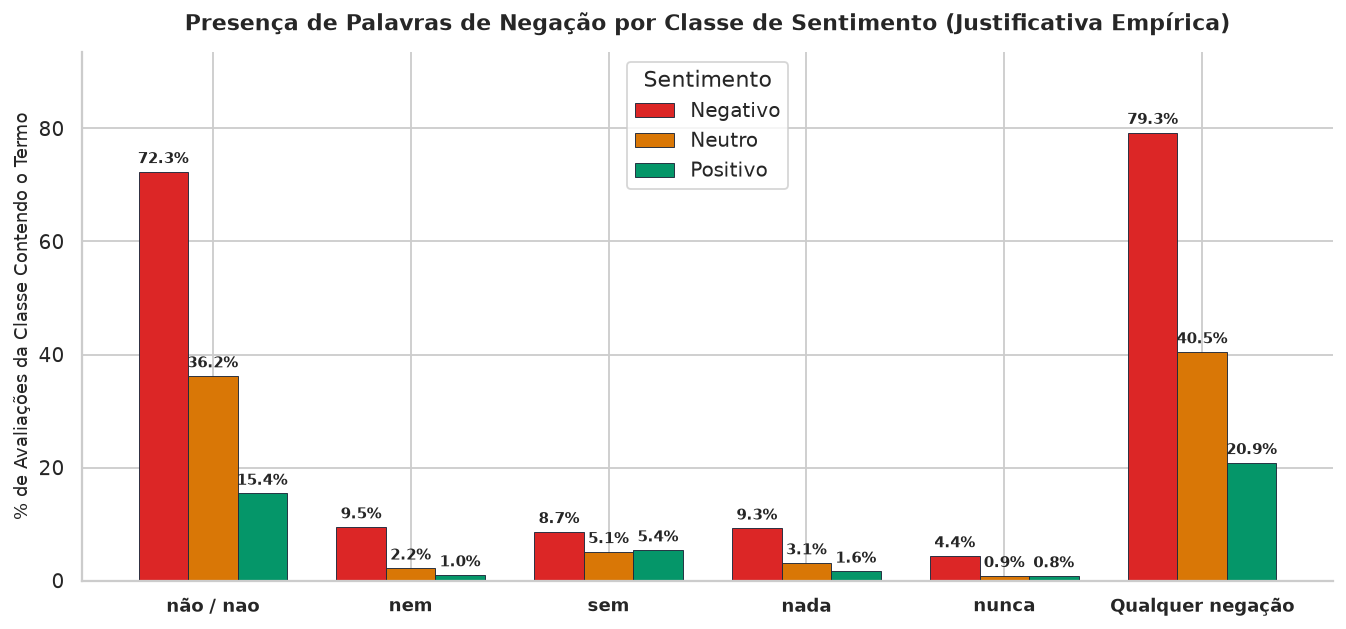

In [5]:
neg_patterns = {
    "não / nao": r"\b(?:não|nao)\b",
    "nem": r"\bnem\b",
    "sem": r"\bsem\b",
    "nada": r"\bnada\b",
    "nunca": r"\bnunca\b",
    "Qualquer negação": r"\b(?:não|nao|nem|nunca|jamais|nada|nenhum|nenhuma|ninguém|ninguem|tampouco|sem)\b",
}

neg_rows = []
for label, pat in neg_patterns.items():
    has_term = df["review_text_clean"].str.contains(pat, regex=True)
    row = {"Termo": label}
    for sent in SENTIMENT_ORDER:
        mask_s = df["sentiment"] == sent
        row[sent] = round(100.0 * has_term[mask_s].mean(), 2)
    neg_rows.append(row)

df_neg_impact = pd.DataFrame(neg_rows)
display(df_neg_impact)

# Gráfico 5: Impacto das palavras de negação por classe
fig, ax = plt.subplots(figsize=(10.5, 5.0))
x = np.arange(len(df_neg_impact))
width = 0.25

for i, sent in enumerate(SENTIMENT_ORDER):
    vals = df_neg_impact[sent].values
    bars = ax.bar(x + (i - 1) * width, vals, width, label=sent, color=PALETTE_SENTIMENT[sent], edgecolor="#1E293B", linewidth=0.5)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.9, f"{v:.1f}%", ha="center", va="bottom", fontsize=8.2, fontweight="bold")

ax.set_xticks(x)
ax.set_xticklabels(df_neg_impact["Termo"], fontsize=9.8, fontweight="bold")
ax.set_ylabel("% de Avaliações da Classe Contendo o Termo", fontsize=10)
ax.set_title("Presença de Palavras de Negação por Classe de Sentimento (Justificativa Empírica)", fontsize=12, fontweight="bold", pad=12)
ax.set_ylim(0, df_neg_impact[SENTIMENT_ORDER].values.max() * 1.18)
ax.legend(title="Sentimento", frameon=True)
sns.despine()
plt.tight_layout()
fig.savefig(FIGURES_DIR / "05_impacto_negacoes.png", dpi=300)
plt.show()


---
## 4. Palavras Mais Frequentes (Antes vs. Depois de Stopwords) e Bigramas por Classe

Além dos unigramas, inspecionamos os **Top 15 bigramas** por sentimento — antecipando para a **Pessoa 2** como `ngram_range=(1, 2)` captura expressões altamente polarizadas como `"não recomendo"`, `"não funciona"`, `"muito bom"` e `"antes prazo"`.


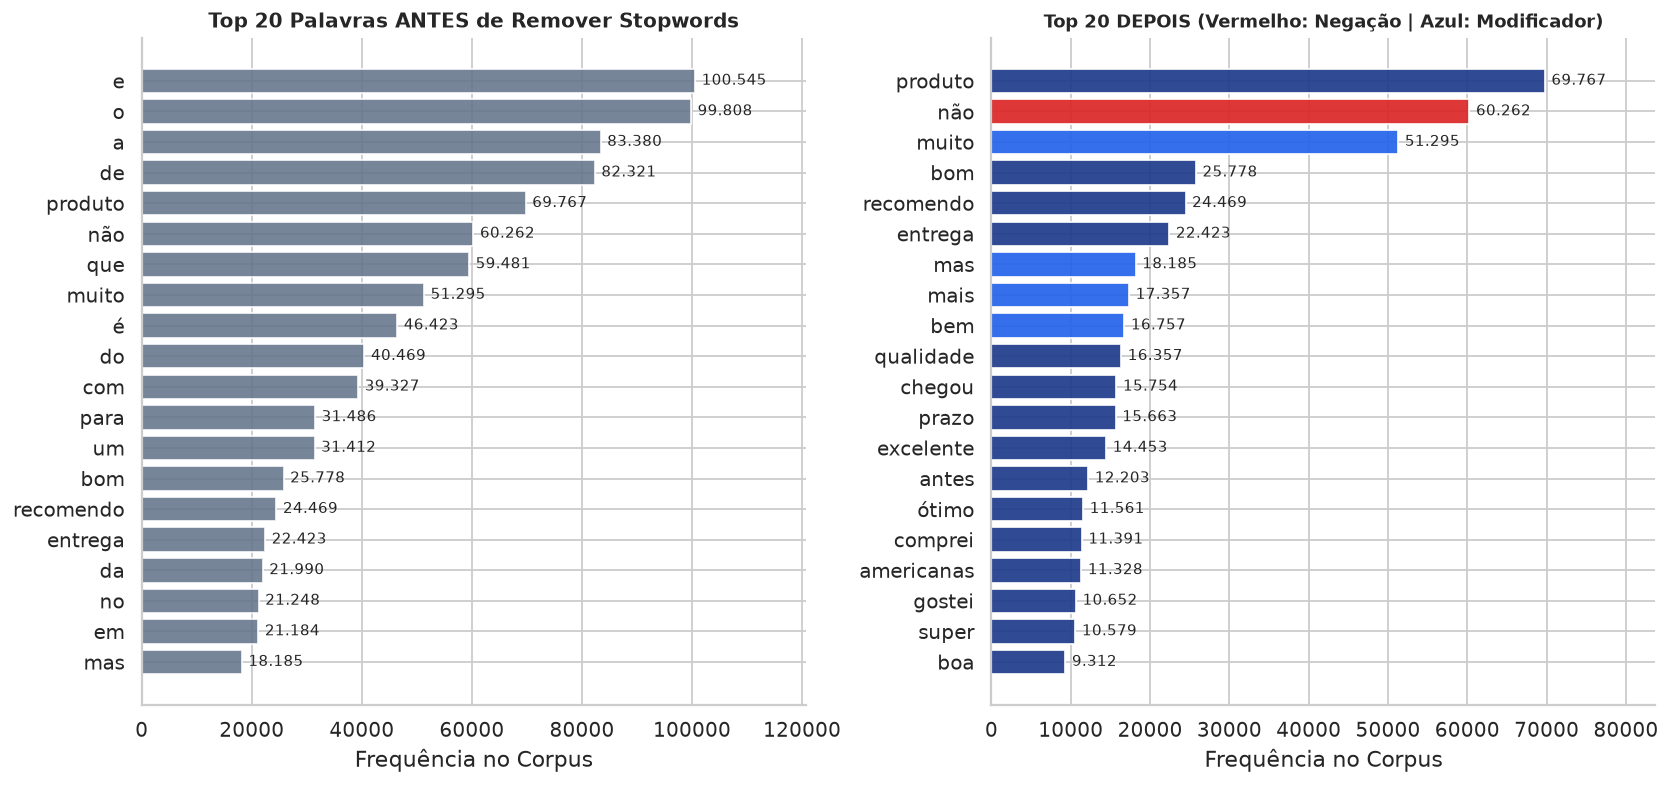

In [6]:
# Gráfico 6: Top 20 palavras antes vs depois da remoção de stopwords (protegendo negações)
top20_before = tokens_before.most_common(20)
top20_after = tokens_after.most_common(20)

fig, axes = plt.subplots(1, 2, figsize=(13.0, 6.2))

# Antes
w_b, c_b = zip(*top20_before[::-1])
axes[0].barh(w_b, c_b, color="#64748B", alpha=0.88)
axes[0].set_title("Top 20 Palavras ANTES de Remover Stopwords", fontsize=11.2, fontweight="bold")
axes[0].set_xlabel("Frequência no Corpus")
for idx, v in enumerate(c_b):
    axes[0].text(v + max(c_b) * 0.012, idx, f"{v:,}".replace(",", "."), va="center", fontsize=8.2)
axes[0].set_xlim(0, max(c_b) * 1.2)
sns.despine(ax=axes[0])

# Depois (destacando negações e modificadores preservados)
w_a, c_a = zip(*top20_after[::-1])
colors_after = [
    "#DC2626" if w in NEGATION_WORDS else ("#2563EB" if w in POLARITY_MODIFIERS else "#1E3A8A")
    for w in w_a
]
axes[1].barh(w_a, c_a, color=colors_after, alpha=0.92)
axes[1].set_title("Top 20 DEPOIS (Vermelho: Negação | Azul: Modificador)", fontsize=10.2, fontweight="bold")
axes[1].set_xlabel("Frequência no Corpus")
for idx, v in enumerate(c_a):
    axes[1].text(v + max(c_a) * 0.012, idx, f"{v:,}".replace(",", "."), va="center", fontsize=8.2)
axes[1].set_xlim(0, max(c_a) * 1.2)
sns.despine(ax=axes[1])

plt.tight_layout()
fig.savefig(FIGURES_DIR / "06_top_palavras_antes_depois_stopwords.png", dpi=300, bbox_inches="tight")
plt.show()


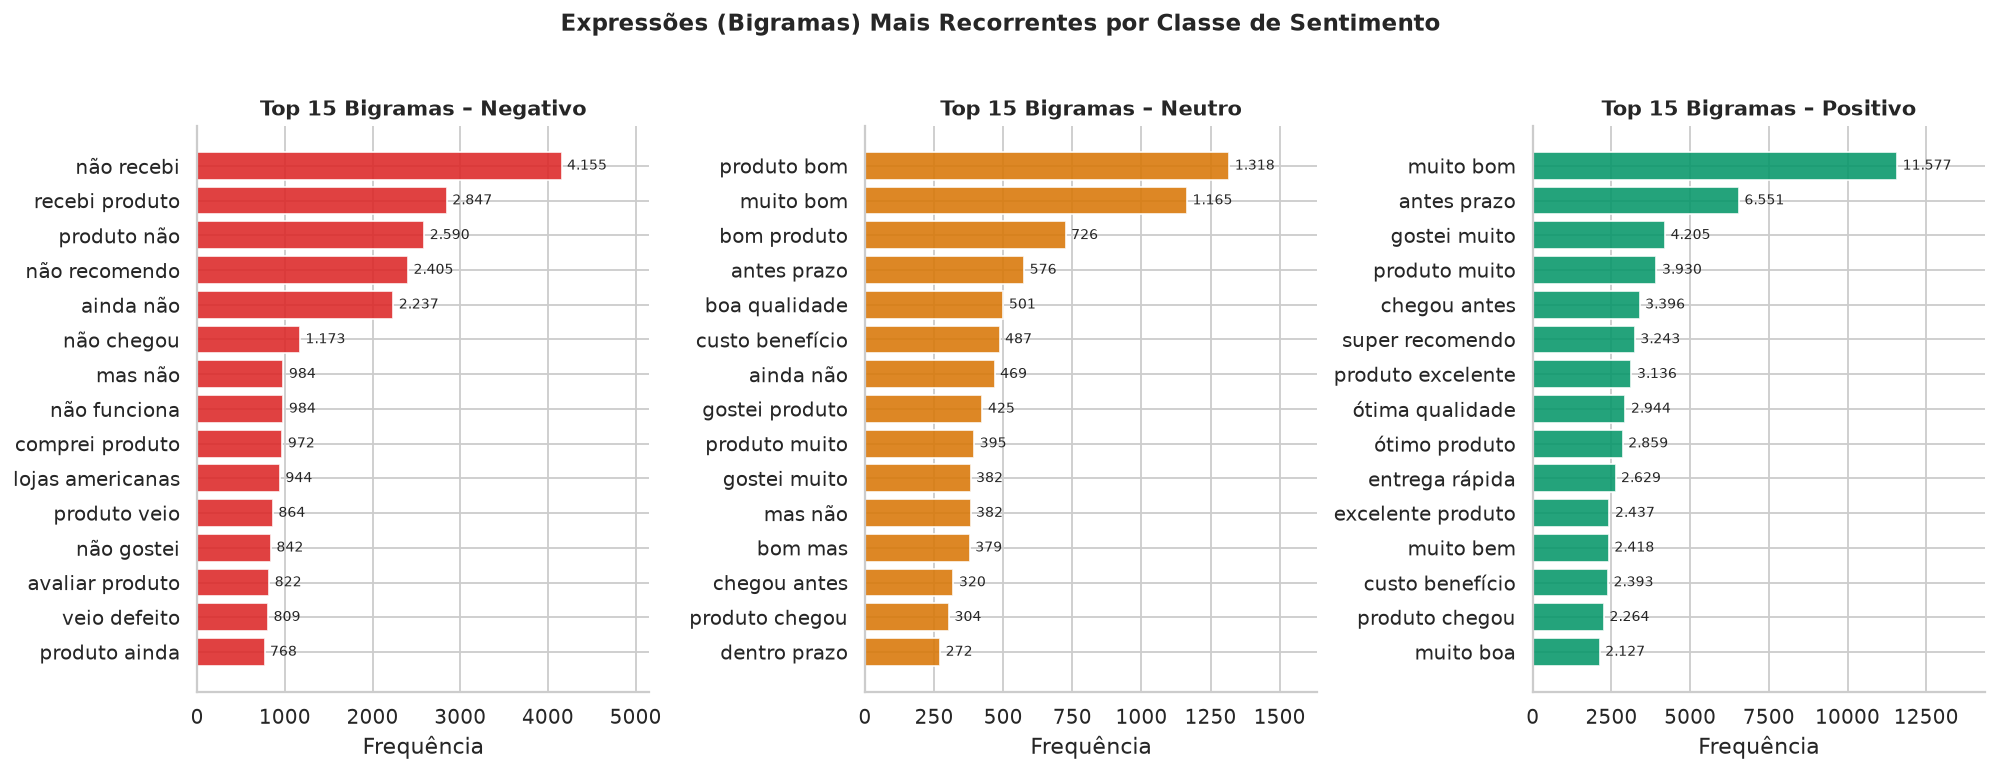

,Negativo,Neutro,Positivo
0,não (37.970),produto (8.180),produto (39.183)
1,produto (22.404),não (7.924),muito (38.938)
2,muito (7.253),bom (5.547),recomendo (19.789)
3,recebi (6.757),muito (5.104),bom (18.670)
4,mais (6.721),mas (4.473),entrega (16.136)
5,comprei (6.169),mais (2.973),não (14.368)
6,mas (5.974),bem (2.526),excelente (13.745)
7,americanas (5.280),entrega (2.151),bem (12.235)
8,veio (4.822),recomendo (1.788),qualidade (12.150)
9,ainda (4.739),boa (1.777),prazo (11.896)


In [7]:
# Gráfico 7: Top 15 Bigramas por classe de sentimento
fig, axes = plt.subplots(1, 3, figsize=(15.5, 5.8))
top_bigrams_by_class = {}
top_unigrams_by_class = {}

for ax, sent in zip(axes, SENTIMENT_ORDER):
    texts_s = df.loc[df["sentiment"] == sent, "review_text_clean"]

    # Unigramas para o resumo
    vec_uni = CountVectorizer(ngram_range=(1, 1), max_features=15, token_pattern=r"[a-záàâãéêíóôõúüç]+")
    X_uni = vec_uni.fit_transform(texts_s)
    uni_counts = np.asarray(X_uni.sum(axis=0)).ravel()
    uni_pairs = sorted(zip(vec_uni.get_feature_names_out(), uni_counts), key=lambda x: x[1], reverse=True)
    top_unigrams_by_class[sent] = [(w, int(c)) for w, c in uni_pairs]

    # Bigramas para visualização
    vec_bi = CountVectorizer(ngram_range=(2, 2), max_features=15, token_pattern=r"[a-záàâãéêíóôõúüç]+")
    X_bi = vec_bi.fit_transform(texts_s)
    bi_counts = np.asarray(X_bi.sum(axis=0)).ravel()
    bi_pairs = sorted(zip(vec_bi.get_feature_names_out(), bi_counts), key=lambda x: x[1], reverse=True)
    top_bigrams_by_class[sent] = [(w, int(c)) for w, c in bi_pairs]

    labels, vals = zip(*bi_pairs[::-1])
    ax.barh(labels, vals, color=PALETTE_SENTIMENT[sent], alpha=0.88)
    ax.set_title(f"Top 15 Bigramas – {sent}", fontsize=11.5, fontweight="bold")
    ax.set_xlabel("Frequência")
    for idx, v in enumerate(vals):
        ax.text(v + max(vals) * 0.015, idx, f"{v:,}".replace(",", "."), va="center", fontsize=8.0)
    ax.set_xlim(0, max(vals) * 1.24)
    sns.despine(ax=ax)

plt.suptitle("Expressões (Bigramas) Mais Recorrentes por Classe de Sentimento", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
fig.savefig(FIGURES_DIR / "07_top_bigramas_por_sentimento.png", dpi=300, bbox_inches="tight")
plt.show()

# Exibir tabela com Top 10 unigramas por classe
pd.DataFrame({
    sent: [f"{w} ({c:,})".replace(",", ".") for w, c in top_unigrams_by_class[sent][:10]]
    for sent in SENTIMENT_ORDER
})


---
## 5. Nuvens de Palavras (*WordClouds*) por Sentimento

Geramos nuvens de palavras independentes para **Negativo**, **Neutro** e **Positivo**, destacando visualmente a diferença vocabular entre reclamações, avaliações mistas e elogios.


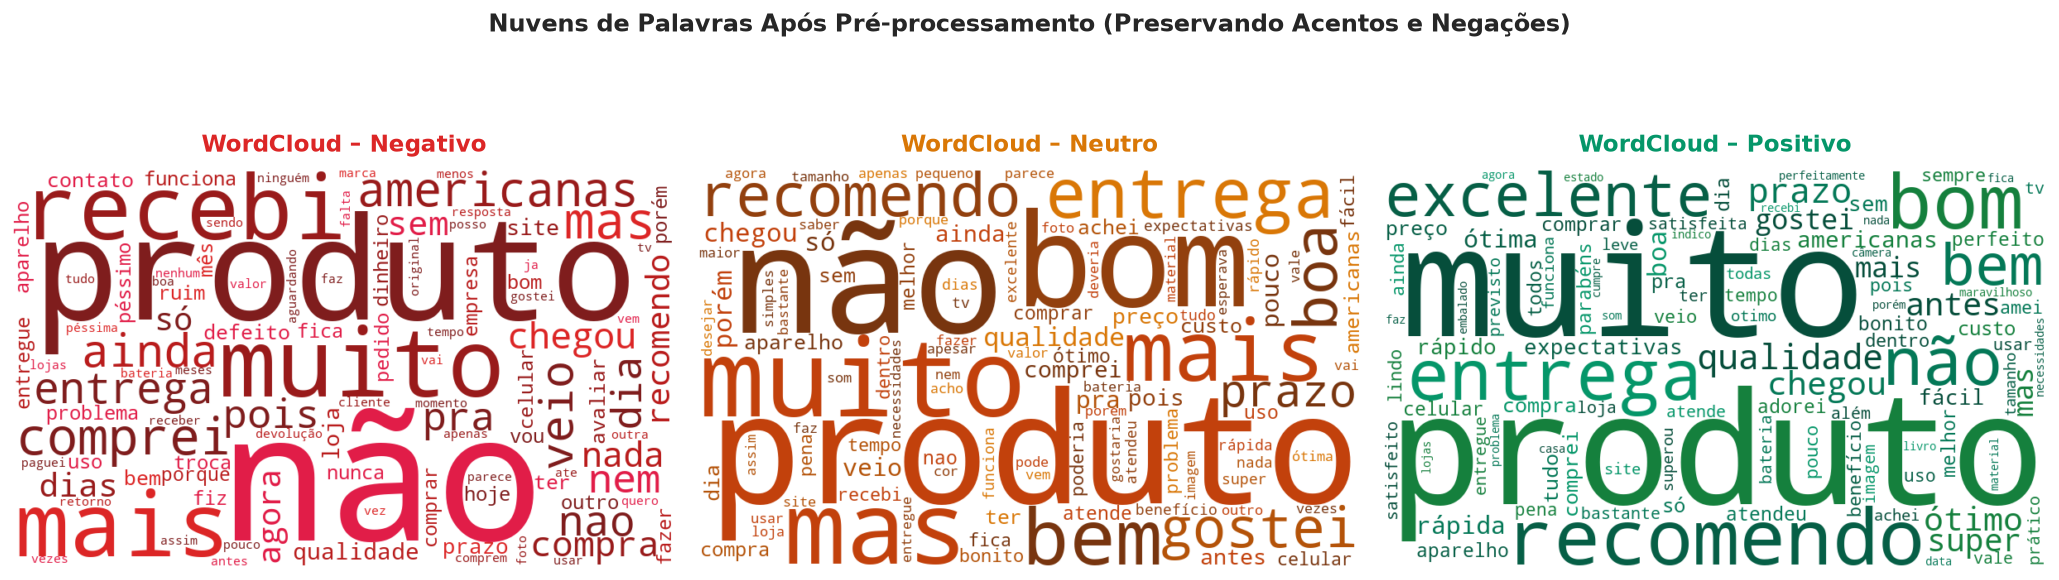

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16.0, 5.0))
# Paletas de alto contraste (evitando tons claros quase brancos no fundo branco)
wc_palettes = {
    "Negativo": ["#7F1D1D", "#991B1B", "#B91C1C", "#DC2626", "#E11D48"],
    "Neutro":   ["#78350F", "#92400E", "#B45309", "#D97706", "#C2410C"],
    "Positivo": ["#064E3B", "#065F46", "#047857", "#059669", "#15803D"],
}

def make_color_func(palette_list):
    def _color_func(word, font_size, position, orientation, random_state=None, **kwargs):
        idx = random_state.randint(0, len(palette_list) - 1) if random_state else 0
        return palette_list[idx]
    return _color_func

for ax, sent in zip(axes, SENTIMENT_ORDER):
    freq_sent = Counter()
    for txt in df.loc[df["sentiment"] == sent, "review_text_clean"]:
        freq_sent.update(txt.split())

    wc = WordCloud(
        width=800,
        height=480,
        background_color="white",
        color_func=make_color_func(wc_palettes[sent]),
        max_words=100,
        random_state=42,
        prefer_horizontal=0.85,
    ).generate_from_frequencies(freq_sent)

    ax.imshow(wc, interpolation="bilinear")
    ax.axis("off")
    ax.set_title(f"WordCloud – {sent}", fontsize=12.5, fontweight="bold", color=PALETTE_SENTIMENT[sent], pad=10)

plt.suptitle("Nuvens de Palavras Após Pré-processamento (Preservando Acentos e Negações)", fontsize=13.5, fontweight="bold", y=1.01)
plt.tight_layout()
fig.savefig(FIGURES_DIR / "08_wordclouds_por_sentimento.png", dpi=300, bbox_inches="tight")
plt.show()


---
## 6. Exportação dos Dados Pré-processados e Resumo para Pessoa 2 e Pessoa 3

Salvamos:
1. `data/b2w_processed_full.parquet`: conjunto completo limpo e pré-processado (ignorado no Git via `.gitignore`).
2. `data/b2w_processed_30k.parquet`: amostra estratificada de 30.000 avaliações (útil para testes rápidos da Pessoa 2).
3. `reports/preprocessing_summary.json`: resumo estruturado de vocabulário, stopwords protegidas, exemplos antes/depois, impacto das negações e Top palavras/bigramas para uso direto no Relatório e na Aba 1 do Streamlit (Pessoa 3).


In [9]:
cols_export = [
    "review_text_original",
    "review_text_clean",
    "overall_rating",
    "sentiment",
    "sentiment_id",
    "site_category_lv1",
    "review_title",
    "recommend_to_a_friend",
    "char_count",
    "word_count",
]
df_export = df[cols_export].copy()
df_export_30k = get_stratified_sample(df_export, n_samples=30000, stratify_col="overall_rating", random_state=42)

full_parquet = DATA_DIR / "b2w_processed_full.parquet"
sample_parquet = DATA_DIR / "b2w_processed_30k.parquet"
df_export.to_parquet(full_parquet, index=False)
df_export_30k.to_parquet(sample_parquet, index=False)

preprocessing_summary = {
    "final_rows_after_preprocessing": int(len(df_export)),
    "removed_empty_after_preprocessing": int(audit.get("removed_empty_after_preprocessing", 0)),
    "nltk_raw_stopwords_count": int(len(raw_sw)),
    "custom_stopwords_count": int(len(custom_sw)),
    "protected_terms_removed_from_nltk": protected_from_nltk,
    "vocabulary_stats": {
        "total_tokens_before_stopwords": int(total_tok_before),
        "total_tokens_after_preprocessing": int(total_tok_after),
        "token_reduction_pct": round(100.0 * (1 - total_tok_after / total_tok_before), 2),
        "unique_vocab_before": int(vocab_before),
        "unique_vocab_after": int(vocab_after),
        "accented_tokens_after": int(accented_tokens_after),
        "accented_tokens_pct": round(100.0 * accented_tokens_after / total_tok_after, 2),
        "accented_vocab_after": int(accented_vocab_after),
    },
    "negation_presence_pct_by_sentiment": df_neg_impact.to_dict(orient="records"),
    "top20_words_before_stopwords": [[w, int(c)] for w, c in top20_before],
    "top20_words_after_stopwords": [[w, int(c)] for w, c in top20_after],
    "top15_unigrams_by_sentiment": top_unigrams_by_class,
    "top15_bigrams_by_sentiment": top_bigrams_by_class,
    "comparison_examples": df_comparacao.to_dict(orient="records"),
}

summary_path = REPORTS_DIR / "preprocessing_summary.json"
with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(preprocessing_summary, f, ensure_ascii=False, indent=2)

print(f"[OK] Corpus completo salvo em: {full_parquet} ({len(df_export):,} linhas)")
print(f"[OK] Amostra 30k salva em:     {sample_parquet} ({len(df_export_30k):,} linhas)")
print(f"[OK] Resumo PLN salvo em:      {summary_path}")


[OK] Corpus completo salvo em: C:\Users\Guilherme\Documents\IA\projeto\data\b2w_processed_full.parquet (126,690 linhas)
[OK] Amostra 30k salva em:     C:\Users\Guilherme\Documents\IA\projeto\data\b2w_processed_30k.parquet (30,000 linhas)
[OK] Resumo PLN salvo em:      C:\Users\Guilherme\Documents\IA\projeto\reports\preprocessing_summary.json
